<a href="https://colab.research.google.com/github/Bauer136/fiat500-resale-regression/blob/main/FiatFumblers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IMPORTS

In [8]:
from pathlib import Path
#This import helps us work with files and folders, letting us grab information easily
from time import perf_counter
#A precise stopwatch, used to time how long each model takes to train and predict

import matplotlib.pyplot as plt
#This import contains functions for graphing data
import numpy as np
#This is a math import, gives us arrays, matrices, mathematical operations, linear algebra, numerical calculations
import pandas as pd
#Gives us the ability to create data frames and tables to store/organize data
import seaborn as sns
#It is built on top of matplotlib to make graphing statistical data easier and gives us more options

from sklearn.dummy import DummyRegressor
#Very simple baseline machine learning model
from sklearn.linear_model import LinearRegression
#Another learning model but this time one focused on Linear Regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#This gives us a way to measure how the learning models run
from sklearn.model_selection import train_test_split
#This helps us separate training, validation and test data for machine learning
from sklearn.preprocessing import StandardScaler
#This standardizes features so they are centered around a mean of 0, and generally have a standard deviation of 1
from sklearn.pipeline import Pipeline
#Chains preprocessing and a model so preprocessing is only ever fitted on training data
from sklearn.impute import SimpleImputer
#Fills in missing values (our data has none, but the pipeline still needs one)
from sklearn.neighbors import KNeighborsRegressor
#K-nearest neighbours for a number target: predicts a car's price from the prices of the most similar training cars

from google.colab import drive
drive.mount('/content/drive')
car_path = Path('/content/drive/MyDrive/FiatFumblers/properData.txt')
#On Colab the data comes from the shared FiatFumblers folder (needs a shortcut in your My Drive)

SEED = 42
#Fixed random seed so the split is the same every time the notebook runs
sns.set_theme(style='whitegrid', context='notebook')
#Changes how the graphs look, basically just a style
pd.set_option('display.max_columns', 20)
#This is just how pandas is displayed to us, more style choices
plt.rcParams["figure.dpi"] = 110

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


ORGANIZING DATA

In [9]:
columns = ['Model', 'Engine Power', 'Age In Days', 'Kilometers', 'Previous Owners', 'Lat', 'Lon', 'Price']
fiat_data = pd.read_csv(car_path, header=None, names=columns)

TARGET = 'Price'
#Resale price in euros, the value every model predicts

print(f'Missing values: {fiat_data.isna().sum().sum()}')
#No gaps in our data, so nothing needs filling here; the imputer in the split step guards against future gaps

print(f'Duplicate rows dropped: {fiat_data.duplicated().sum()}')
fiat_data = fiat_data.drop_duplicates()
#Identical listings are removed before splitting so the same car can't end up in both train and test

print(f'Rows: {fiat_data.shape[0]:,} | Columns: {fiat_data.shape[1]}')
display(fiat_data.head())
display(fiat_data.describe().T.round(1))

Missing values: 0
Duplicate rows dropped: 18
Rows: 1,520 | Columns: 8


,Model,Engine Power,Age In Days,Kilometers,Previous Owners,Lat,Lon,Price
0,lounge,62,3074,61000,1,45.518150,10.35067,8450
1,lounge,51,790,29395,1,41.903221,12.49565,8650
2,lounge,51,821,28220,1,41.903221,12.49565,10400
3,lounge,51,397,11997,1,41.903221,12.49565,9999
4,pop,51,366,10295,1,41.903221,12.49565,10100


,count,mean,std,min,25%,50%,75%,max
Engine Power,1520.0,51.9,4.0,51.0,51.0,51.0,51.0,77.0
Age In Days,1520.0,1657.2,1290.9,366.0,670.0,1066.0,2623.8,4658.0
Kilometers,1520.0,53602.5,40181.2,1232.0,20000.0,39162.0,80000.0,235000.0
Previous Owners,1520.0,1.1,0.4,1.0,1.0,1.0,1.0,4.0
Lat,1520.0,43.5,2.1,36.9,41.8,44.4,45.5,46.8
Lon,1520.0,11.6,2.3,7.2,9.5,11.9,12.8,18.4
Price,1520.0,8564.3,1942.8,2500.0,7100.0,9000.0,10000.0,11100.0


EXPLORATORY FIGURES

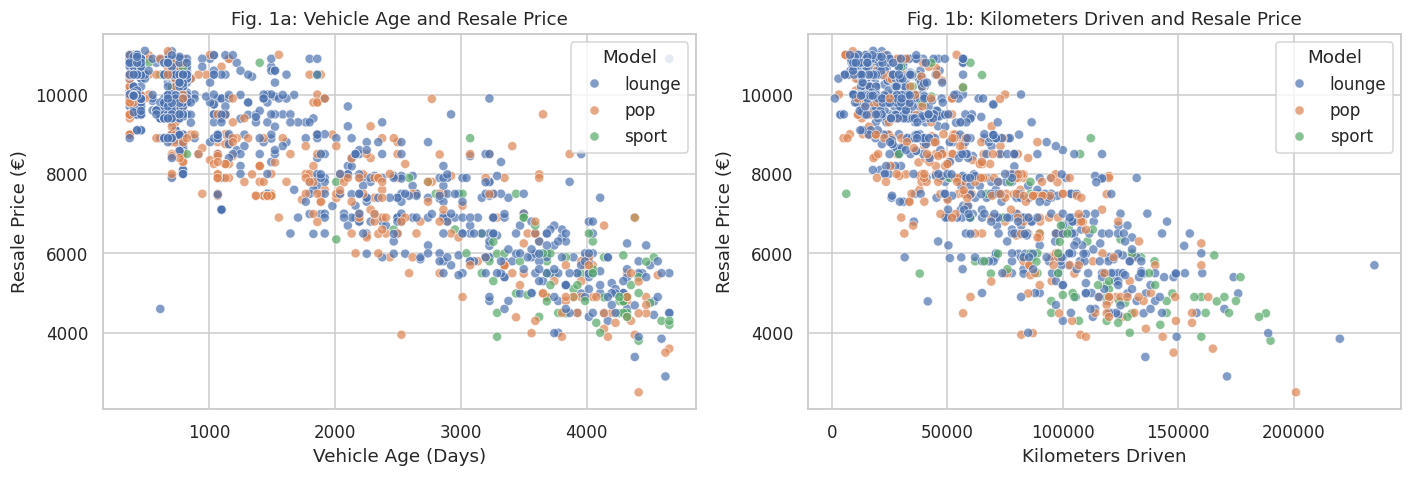

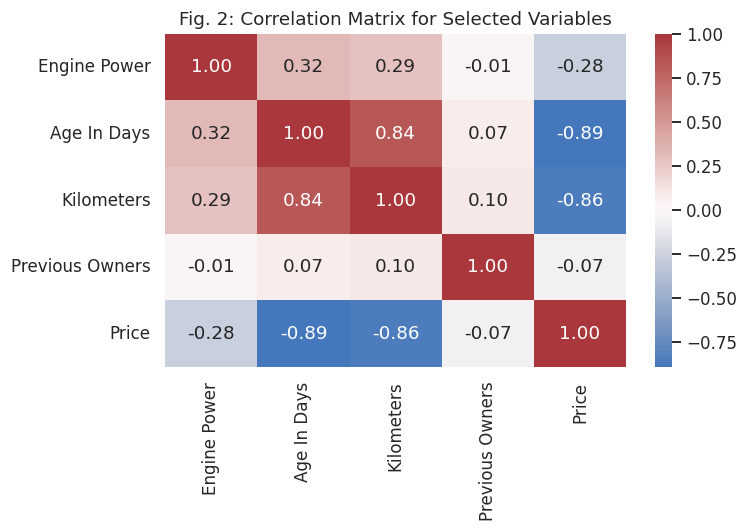

In [10]:
# Select features to analyze
focus = ['Engine Power', 'Age In Days', 'Kilometers', 'Previous Owners', 'Price']

# Create two scatter plots side by side, coloured by trim
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(data=fiat_data, x='Age In Days', y='Price', hue='Model',
                alpha=0.7, ax=axes[0])
axes[0].set_title('Fig. 1a: Vehicle Age and Resale Price')
axes[0].set_xlabel('Vehicle Age (Days)')
axes[0].set_ylabel('Resale Price (€)')

sns.scatterplot(data=fiat_data, x='Kilometers', y='Price', hue='Model',
                alpha=0.7, ax=axes[1])
axes[1].set_title('Fig. 1b: Kilometers Driven and Resale Price')
axes[1].set_xlabel('Kilometers Driven')
axes[1].set_ylabel('Resale Price (€)')

plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(fiat_data[focus].corr(), annot=True,
            cmap='vlag', center=0, fmt='.2f')

plt.title('Fig. 2: Correlation Matrix for Selected Variables')
plt.tight_layout()
plt.show()

SPLITTING DATA

In [11]:
X = pd.get_dummies(fiat_data.drop(columns=TARGET), columns=['Model'], drop_first=True, dtype=int)
y = fiat_data[TARGET]
#Model becomes Model_pop and Model_sport (0/1); a lounge car has 0 in both

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=fiat_data['Model'], random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=fiat_data.loc[X_temp.index, 'Model'], random_state=SEED)
#70% train / 15% validation / 15% test; the second split cuts the remaining 30% in half

splits = {'Train': (X_train, y_train), 'Validation': (X_val, y_val), 'Test': (X_test, y_test)}
split_table = pd.DataFrame.from_dict({
    name: {'Rows': len(y_s), 'Share (%)': round(100 * len(y_s) / len(y), 1), 'Mean Price (€)': round(y_s.mean()),
           **fiat_data.loc[X_s.index, 'Model'].value_counts().to_dict()}
    for name, (X_s, y_s) in splits.items()
}, orient='index')
print('Table 1: Frozen data split')
display(split_table)

Table 1: Frozen data split


,Rows,Share (%),Mean Price (€),lounge,pop,sport
Train,1064,70.0,8562,755,249,60
Validation,228,15.0,8526,162,53,13
Test,228,15.0,8614,162,54,12


BASELINES

In [12]:
def baseline(model):
    return Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('model', model)])
#Every model gets the same fresh preprocessing: fill gaps with the median, then standardize
#Nothing is fitted here; calling .fit(X_train, ...) later fits the imputer and scaler on the training rows only

In [14]:
baselines = {
    'Dummy (mean price)': baseline(DummyRegressor(strategy='mean')),
    'MLR (all features)': baseline(LinearRegression()),
    'KNN (k=5)': baseline(KNeighborsRegressor(n_neighbors=5)),
}
#MLR and KNN are our two baselines; the dummy is only the reference point for the improvement column

rows, val_preds = [], {}
for name, pipe in baselines.items():
    start = perf_counter()
    pipe.fit(X_train, y_train)
    train_time = perf_counter() - start

    start = perf_counter()
    val_pred = val_preds[name] = pipe.predict(X_val)
    predict_time = perf_counter() - start

    fitted = pipe.named_steps['model']
    if hasattr(fitted, 'coef_'):
        n_params = fitted.coef_.size + 1
    elif isinstance(fitted, DummyRegressor):
        n_params = 1
    else:
        n_params = 0
    #Linear models learn one weight per input column plus an intercept; the dummy learns one number (the mean); KNN learns none, it stores the training rows

    rows.append({
        'Model': name,
        'Val MAE (€)': mean_absolute_error(y_val, val_pred),
        'Val RMSE (€)': np.sqrt(mean_squared_error(y_val, val_pred)),
        'Val R²': r2_score(y_val, val_pred),
        'Train MAE (€)': mean_absolute_error(y_train, pipe.predict(X_train)),
        'Parameters': n_params,
        'Train time (ms)': 1000 * train_time,
        'Predict time (ms)': 1000 * predict_time,
    })

results = pd.DataFrame(rows).set_index('Model')
results['MAE improvement vs Dummy (%)'] = 100 * (1 - results['Val MAE (€)'] / results.loc['Dummy (mean price)', 'Val MAE (€)'])
#Prediction time is measured on the validation set, because the test set stays untouched until Stage 3

print('Table 2: Baseline comparison on the validation set')
display(results.round({'Val MAE (€)': 0, 'Val RMSE (€)': 0, 'Val R²': 3, 'Train MAE (€)': 0,
                       'Train time (ms)': 2, 'Predict time (ms)': 2, 'MAE improvement vs Dummy (%)': 1}))

Table 2: Baseline comparison on the validation set


,Val MAE (€),Val RMSE (€),Val R²,Train MAE (€),Parameters,Train time (ms),Predict time (ms),MAE improvement vs Dummy (%)
Model,,,,,,,,
Dummy (mean price),1674.0,1972.0,-0.000,1658.0,1,8.76,2.04,0.0
MLR (all features),630.0,817.0,0.828,587.0,9,5.67,1.84,62.3
KNN (k=5),671.0,935.0,0.775,502.0,0,6.97,6.76,59.9


Where the Baselines Fail

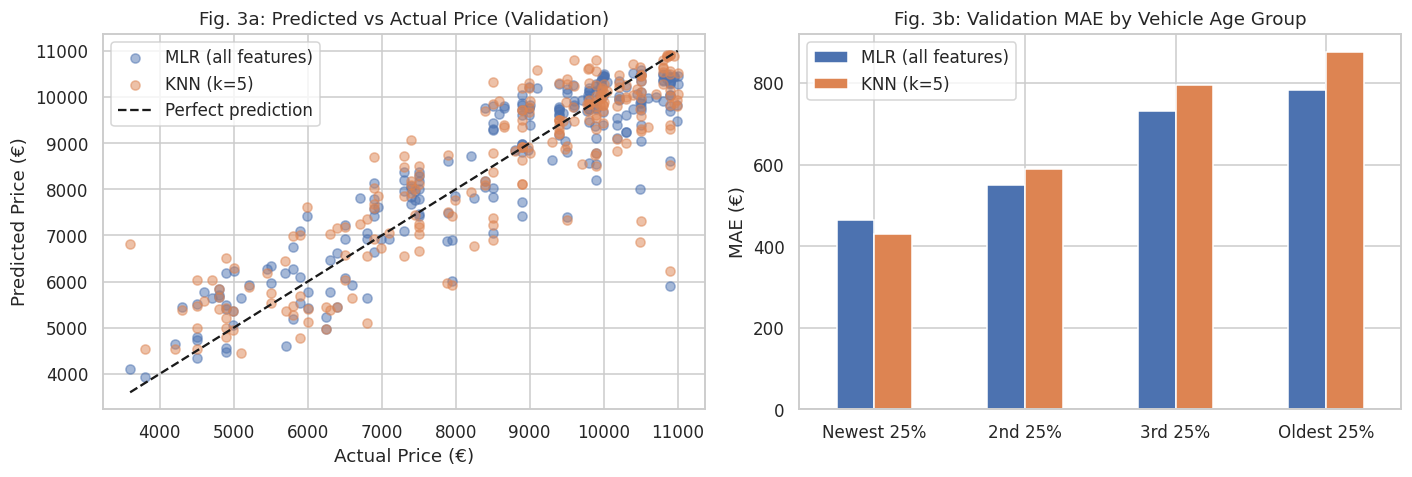

Table 3: Validation MAE (€) by vehicle age group


,MLR (all features),KNN (k=5)
Age In Days,,
Newest 25%,464.0,429.0
2nd 25%,549.0,589.0
3rd 25%,731.0,794.0
Oldest 25%,783.0,877.0


In [7]:
compare = ['MLR (all features)', 'KNN (k=5)']
#Our two baselines; their validation predictions were saved in val_preds
age_group = pd.qcut(X_val['Age In Days'], 4, labels=['Newest 25%', '2nd 25%', '3rd 25%', 'Oldest 25%'])
#Splits the validation cars into four equal-sized groups by age

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for name in compare:
    axes[0].scatter(y_val, val_preds[name], alpha=0.5, label=name)
axes[0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'k--', label='Perfect prediction')
axes[0].set_title('Fig. 3a: Predicted vs Actual Price (Validation)')
axes[0].set_xlabel('Actual Price (€)')
axes[0].set_ylabel('Predicted Price (€)')
axes[0].legend()

mae_by_age = pd.DataFrame({name: np.abs(y_val - val_preds[name]) for name in compare}).groupby(age_group, observed=True).mean()
mae_by_age.plot.bar(ax=axes[1], rot=0)
axes[1].set_title('Fig. 3b: Validation MAE by Vehicle Age Group')
axes[1].set_xlabel('')
axes[1].set_ylabel('MAE (€)')

plt.tight_layout()
plt.show()

print('Table 3: Validation MAE (€) by vehicle age group')
display(mae_by_age.round(0))

### Conclusion and next risk

**Conclusion.** MLR is the stronger of our two baselines. Its validation MAE is €630 (R² 0.83), against €671 (R² 0.78) for KNN, and both are about 60% better than always predicting the average price (€1,674) (Table 2). KNN fits the training cars more closely than MLR (training MAE €502 vs €587) but does worse on validation, a sign that with k=5 it partly memorizes the training data instead of generalizing.

**Unresolved risk.** Errors grow with the car's age for both models. MLR's MAE rises from €464 for the newest quarter of cars to €783 for the oldest (Table 3, Fig. 3b). A straight-line model assumes every car loses value at the same steady rate. It also cannot follow the €11,100 price ceiling, so it underpredicts the most expensive near-new cars (Fig. 3a). In Stage 2 we will test whether tree-based models and an MLP capture this non-linear depreciation, using the same split and metrics.
